1. Prepare features for machine learning

In [3]:
# Import required libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

df = pd.read_csv("cleaned_manufacturing_quality.csv")
# Check the dataset
print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["quality_status"].value_counts())

# Select input features
features = [
    "line", "shift", "quantity", "machine",
    "age_band", "operating_hours", "temperature",
    "pressure", "speed", "supplier",
    "material_grade"
]

X = df[features]
y = df["quality_status"]

print("\nInput features:", X.shape)
print("Target:", y.shape)

Dataset shape: (1200, 17)

Target distribution:
quality_status
Good         632
Defective    568
Name: count, dtype: int64

Input features: (1200, 11)
Target: (1200,)


2. Split the dataset

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 960
Testing records: 240


3. Train the model

In [5]:

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


4. Evaluate the model

Accuracy: 0.5917

Classification Report:
              precision    recall  f1-score   support

   Defective       0.57      0.57      0.57       114
        Good       0.61      0.61      0.61       126

    accuracy                           0.59       240
   macro avg       0.59      0.59      0.59       240
weighted avg       0.59      0.59      0.59       240



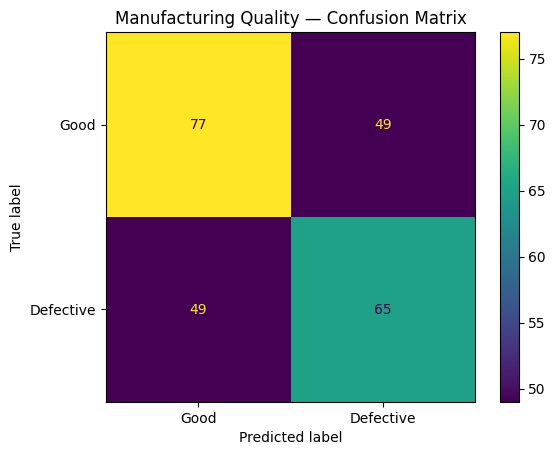

In [6]:

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(
    y_test, y_pred, labels=["Good", "Defective"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Good", "Defective"]
)
display.plot()
plt.title("Manufacturing Quality — Confusion Matrix")
plt.show()